# Xenium mouse kidney - ShamR

In [1]:
from pathlib import Path
import cellman.spatial as cms

ROOT       = "/bce/groups/pnucolab/analysis/l202255179/UNNAMED"
XENIUM_DIR = f"{ROOT}/cellman_paper/data/xenium/ShamR-output-XETG00063__0005295__Region_6__20230717__191520"

STORE_ROOT = f"{ROOT}/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR"
ZARR       = f"{STORE_ROOT}/spatialdata.zarr"
CROPS      = f"{STORE_ROOT}/spatialdata_crops"
STORE      = f"{STORE_ROOT}/cellman_spatial"         
SCRIPTS    = f"{ROOT}/CeLLMan/cellman/spatial/scripts"

DEVICE     = "cuda:1"            
NCORES     = 30

Path(STORE_ROOT).mkdir(parents=True, exist_ok=True)
print("cellman.spatial", cms.__version__, "| store:", STORE) 

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cellman.spatial 0.1.0 | store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial


## Step 1 — Load the Xenium sample into SpatialData

In [4]:
import spatialdata as sd
import spatialdata_io

if Path(ZARR).exists():
    sdata = sd.read_zarr(ZARR)
    print("loaded existing", ZARR)
else:
    sdata = spatialdata_io.xenium(XENIUM_DIR)
    sdata.write(ZARR)
    print("wrote", ZARR)
sdata

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the default in the next minor release.
  return next(self.gen)
/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/contextlib.py:137: UserWarning: zarr v3 autosharding will be the

wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (84419, 300)
with coordinate systems:
    ▸ 'global'

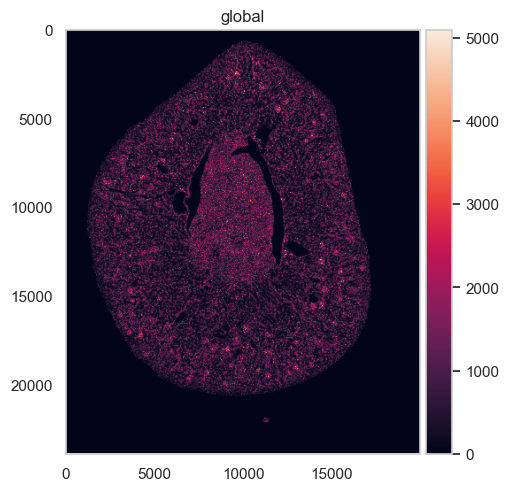

In [5]:
import spatialdata_plot 

IMAGE_KEY  = "morphology_mip"    
sdata.pl.render_images(IMAGE_KEY).pl.show()

## Step 2 — Tile the sample for chunked downsampling

`slice_spatialdata.py` splits the (large) image + transcripts into square tiles so
`downsample_vector(chunked=True, ...)` can stream them. Keeps only transcripts + image.

In [6]:
import subprocess, sys
if not Path(CROPS).exists():
    subprocess.run([sys.executable, f"{SCRIPTS}/slice_spatialdata.py",
                    "--sdata-path", ZARR,
                    "--tile-size", "10000",
                    "--output-dir", CROPS,
                    "--image-key", IMAGE_KEY,
                    "--keep-points", "transcripts",
                    "--drop-labels", "--drop-shapes", "--drop-tables"], check=True)
else:
    print("tiles already exist:", CROPS)

SDATA_PATH    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
TILE_SIZE     : 10000.0
OUTPUT_DIR    : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops
MIN_TILE_SIZE : 5000.0
COORD_SYSTEM  : global

SpatialData loaded:
  images : ['morphology_focus', 'morphology_mip']
  labels : ['cell_labels', 'nucleus_labels']
  points : ['transcripts']
  shapes : ['cell_boundaries', 'nucleus_boundaries']
  tables : ['table']

Global extent: x=[0.00, 19971.00], y=[0.00, 23888.00]
x_edges: ['0.0', '10000.0', '19971.0']
y_edges: ['0.0', '10000.0', '23888.0']
Grid: 2 rows x 2 cols = 4 tiles

[0,0] x=[0.00,10000.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r00_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2760037, cells=0)
[0,1] x=[10000.00,19971.00], y=[0.00,10000.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r00_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=2376664, cells=0)
[1,0] x=[0.00,10000.00], y=[10000.00,23888.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r01_c00.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=4379602, cells=0)
[1,1] x=[10000.00,19971.00], y=[10000.00,23888.00] -> /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops/r01_c01.zarr


/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: UserWarning: The object has `points` element. Depending on the number of points, querying MAY suffer from performance issues. Please consider filtering the object before calling this function by calling the `subset()` method of `SpatialData`.
  return dispatch(args[0].__class__)(*args, **kw)


  -> saved (images=['morphology_mip'], labels=[], points=['transcripts'], shapes=[], tables=[], transcripts=3597645, cells=0)

Done.
  Total grid cells : 4
  Tiles saved      : 4
  Tiles skipped    : 0
  Output directory : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata_crops

Saved files:
  r00_c00.zarr
  r00_c01.zarr
  r01_c00.zarr
  r01_c01.zarr


## Step 3 — `downsample_vector`

Samples representative pixels from the morphology tissue mask and computes the KDE
vector field at each → `normalized_vectors` in the store.

- `revert_image=False`: Xenium morphology is bright-tissue-on-dark. Use `True` for brightfield H&E.

In [ ]:
ds = cms.Dataset(STORE)
analysis = cms.Analysis(ds, ncores=NCORES, verbose=True)

zarr keys: (empty)


In [8]:
adata = analysis.downsample_vector(
    chunked=True,
    sdata_dir=CROPS,
    n_samples=10,
    block_um=10,
    bandwidth=2.5,
    sampling_distance=1.0,
    image_key=IMAGE_KEY,
    revert_image=False,
    gpu_device=DEVICE,
) 

adata

downsample_vector (chunked): 4 sdata stores found.
  r00_c00: otsu=60
  r00_c01: otsu=56
  r01_c00: otsu=60
  r01_c01: otsu=58
  median otsu: 59.0

  [r00_c00]
    kept: 55,585  offset: [0.7139477133750916, 2.325871467590332, 0.0]

  [r00_c01]
    kept: 46,628  offset: [2125.000244140625, 1.1899898052215576, 0.0]

  [r01_c00]
    kept: 83,736  offset: [2.0103771686553955, 2125.00048828125, 0.0]

  [r01_c01]
    kept: 72,634  offset: [2125.00048828125, 2125.00048828125, 0.0]

  total kept (all chunks): 258,583


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


AnnData object with n_obs × n_vars = 258583 × 541
    obs: 'vf_norm'
    obsm: 'spatial'

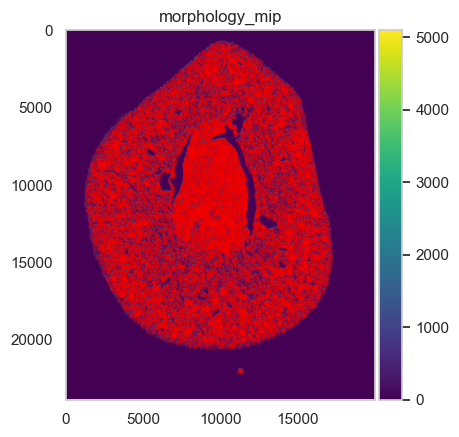

In [13]:
import matplotlib.pyplot as plt
POINTS_KEY = "transcripts"

ds.plot_image(sdata, image_key=IMAGE_KEY, cmap="viridis")
ds.extract_spatialdata_scale(sdata, element_name=POINTS_KEY)
ds.plot_downsampled_vector(s=0.01)
plt.show()

## Step 4 — Clustering

In [ ]:
import rapids_singlecell as rsc

rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=15)
rsc.tl.leiden(adata, resolution=1)

In [ ]:
adata.write_h5ad(f"{STORE}/mouse_kidney_cls.h5ad")

## Step 5 — Agentic annotation (external step)

Cluster → cell-type identity is assigned by the **annotate-mode** skill (LLM + Cell-Ontology
KG), which runs *outside* this notebook and writes h5ad file with `obs['celltype_annotation']`.

/annotate-mode Annotate the h5ad file below using the annotate-expert agent.

- input : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial/mouse_kidney_cls.h5ad
- out   : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial
- tissue : mouse, kidney
- cluster column : leiden 
- virtual env : /bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv
- note : use 5090 GPU on device '1'

/tmp/ipykernel_2029014/474328934.py:6: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)


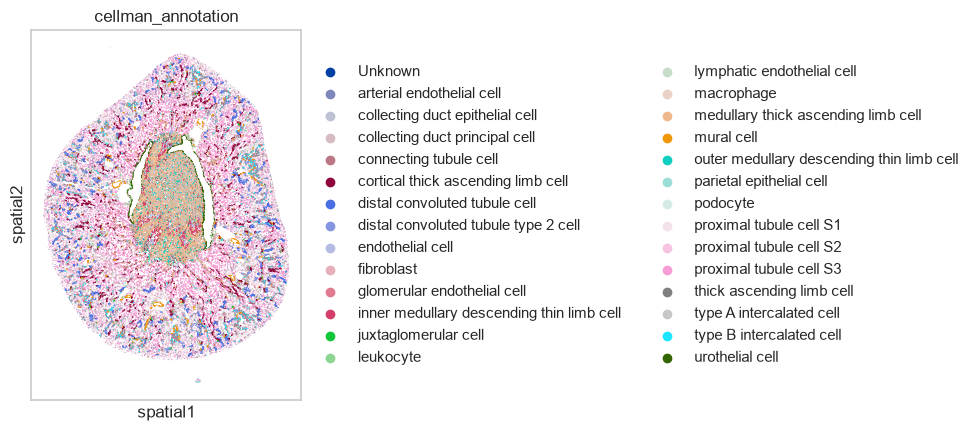

In [3]:
import scanpy as sc

ANNO = f"{STORE}/annotation_out/mouse_kidney_cls_annotated.h5ad" 
if Path(ANNO).exists():
    anno = sc.read_h5ad(ANNO)
    sc.pl.spatial(anno, color="cellman_annotation", spot_size=10)
else:
    anno = None
    print("annotation not found yet — run annotate-mode to produce:", ANNO)

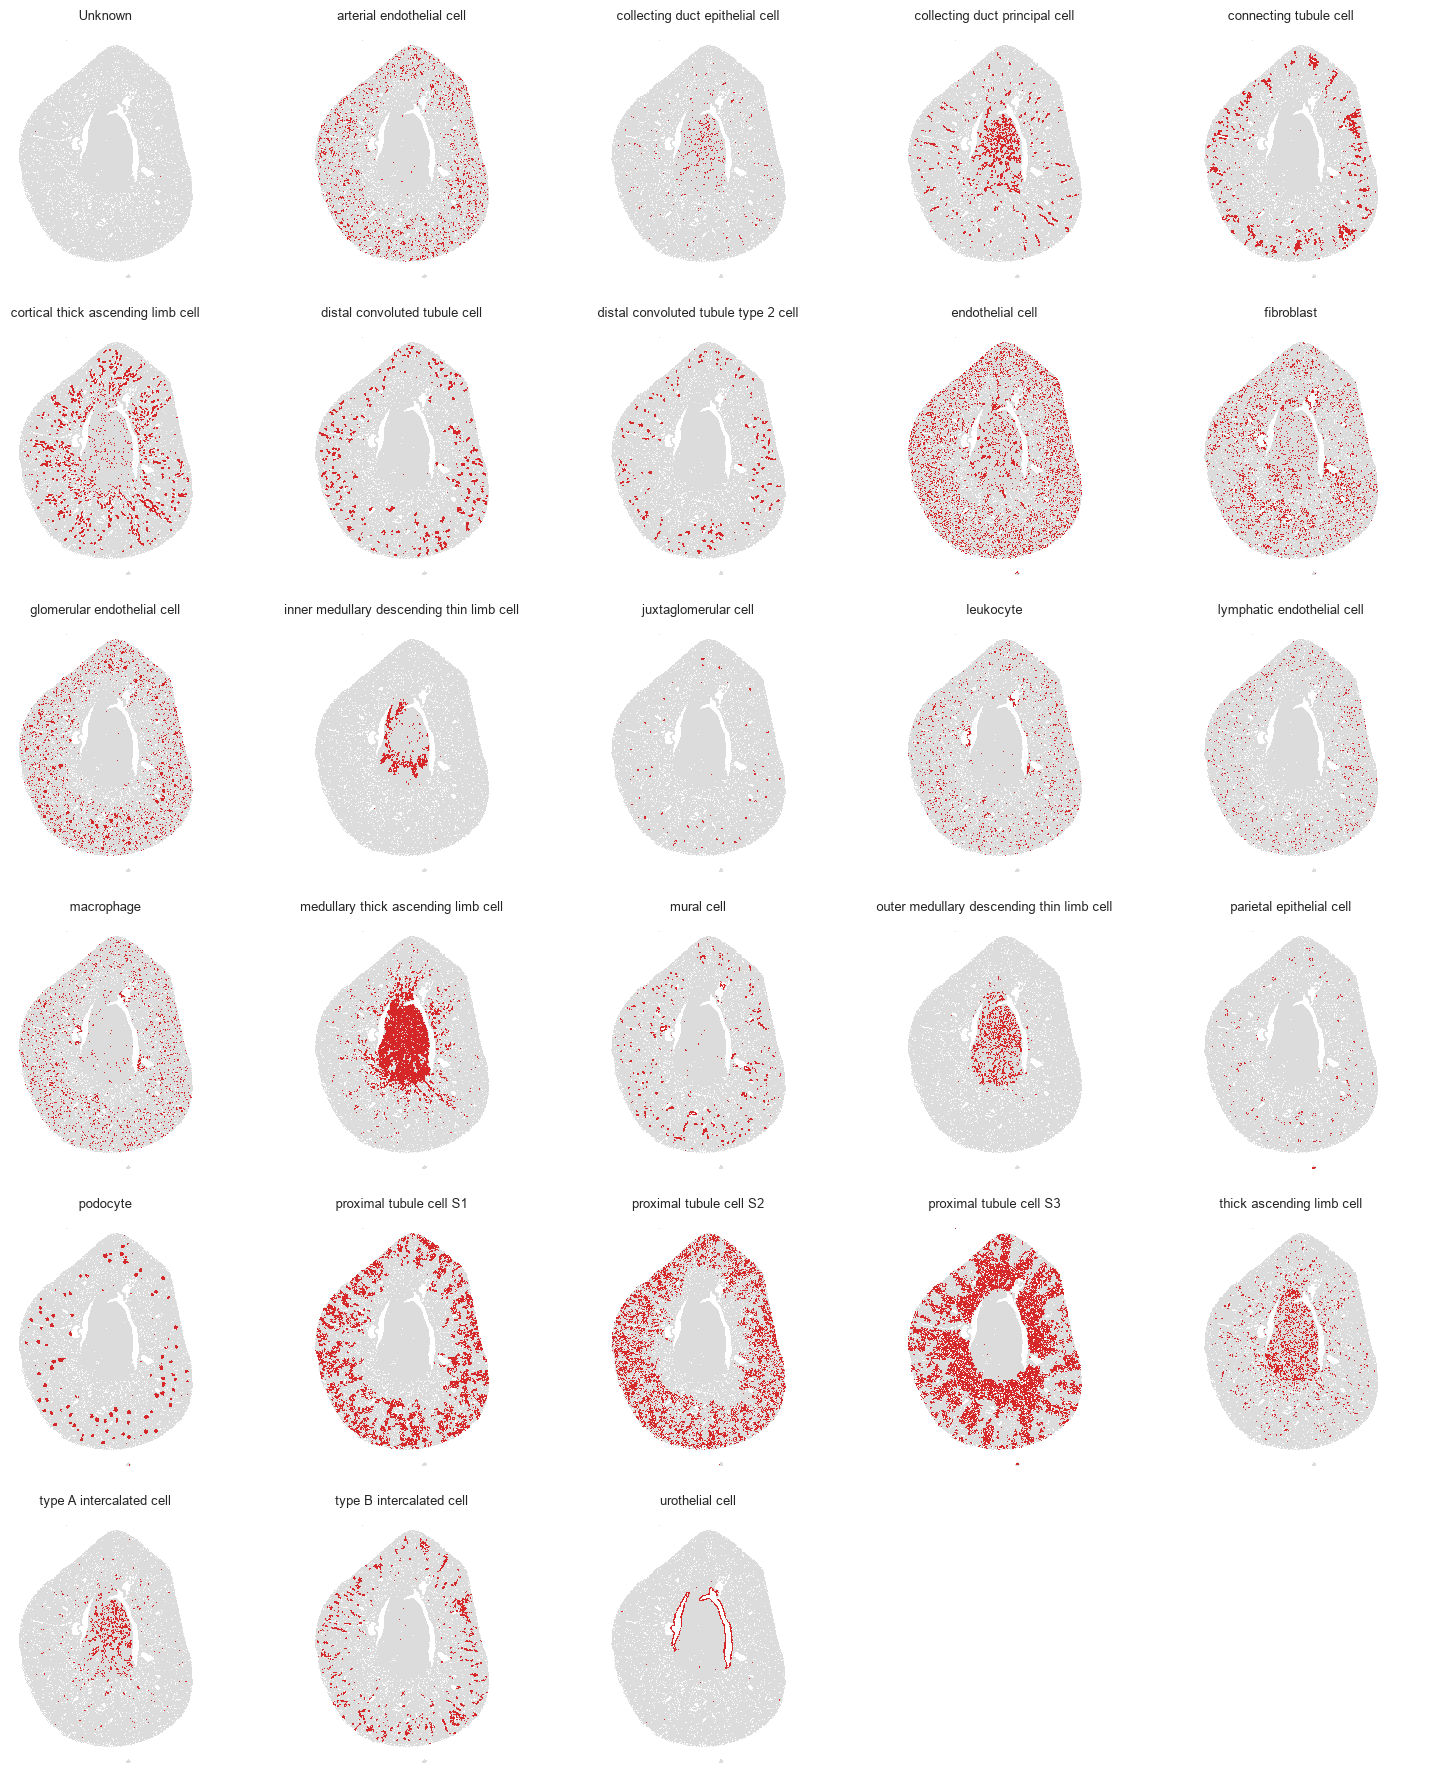

In [4]:
import math, matplotlib.pyplot as plt
COL='cellman_annotation'; PS=0.5; N_COLS=5; BG='#dcdcdc'; FG='#d62728'
xy = anno.obsm['spatial']; labels = anno.obs[COL].astype(str).to_numpy()
cats = list(anno.obs[COL].cat.categories); n=len(cats)
n_cols=min(N_COLS,n); n_rows=math.ceil(n/n_cols)
fig,axes=plt.subplots(n_rows,n_cols,figsize=(3*n_cols,3*n_rows),squeeze=False)
for a_ in axes.flat: a_.set_axis_off()
for i,ct in enumerate(cats):
    a_=axes[i//n_cols,i%n_cols]; m=labels==ct
    a_.scatter(xy[~m,0],xy[~m,1],s=PS,c=BG,linewidths=0,rasterized=True)
    a_.scatter(xy[m,0], xy[m,1], s=PS,c=FG,linewidths=0,rasterized=True)
    a_.set_title(ct,fontsize=9); a_.set_aspect('equal'); a_.invert_yaxis()
fig.tight_layout(); plt.show()

In [50]:
import os, requests

SERVER = os.environ.get("CELLONTO_SERVER_URL", "https://cellman.pnucolab.com")
SPECIES, ORGAN = "mouse", "kidney"

def _fetch_slim(sp, og):
    for base in dict.fromkeys([SERVER, "https://cellman.pnucolab.com"]):
        try:
            j = requests.get(f"{base.rstrip('/')}/module/{sp}/{og}/slim-index", timeout=30).json()
            if isinstance(j, dict) and "terms" in j:
                return j
        except Exception:
            pass
    raise RuntimeError("slim-index fetch failed")

slim = _fetch_slim(SPECIES, ORGAN)
byID = slim["terms"]                                # Concept ID -> term
byL  = {t.get("L"): t for t in byID.values()}       # celltype 이름 -> term

def _collect_up(tid, slots, seen):
    """term tid 와 그 모든 조상(부모 P 체인)의 slot 유전자를 재귀 수집."""
    if tid in seen or tid not in byID:              # 중복/사이클/외부 부모 방지
        return []
    seen.add(tid)
    t = byID[tid]
    g = []
    for s in slots:
        g += (t.get(s) or [])
    for pid in (t.get("P") or []):                  # 부모(들)로 재귀
        g += _collect_up(pid, slots, seen)
    return g

def get_markers(celltypes=None, slots=("R", "DF"), adata=None, include_ancestors=True):
    """celltype 이름 → 마커 리스트. include_ancestors=True 면 부모→루트 마커까지 union."""
    if celltypes is None:
        celltypes = list(byL)
    elif isinstance(celltypes, str):
        celltypes = [celltypes]
    vmap = None
    if adata is not None:
        vmap = {}
        for v in map(str, adata.var_names):
            vmap.setdefault(v.upper(), v)
    out = {}
    for ct in celltypes:
        t = byL.get(ct)
        if t is None:
            continue
        g = []
        for s in slots:                              # 자기 자신의 R/DF
            g += (t.get(s) or [])
        if include_ancestors:                        # 조상들의 R/DF 재귀
            seen = set()
            for pid in (t.get("P") or []):
                g += _collect_up(pid, slots, seen)
        g = list(dict.fromkeys(g))                   # 순서유지 dedup
        if vmap is not None:
            g = [vmap[x.upper()] for x in g if x.upper() in vmap]
        out[ct] = g
    return out


In [8]:
anno.obs['cellman_annotation'].cat.categories

Index(['Unknown', 'arterial endothelial cell',
       'collecting duct epithelial cell', 'collecting duct principal cell',
       'connecting tubule cell', 'cortical thick ascending limb cell',
       'distal convoluted tubule cell', 'distal convoluted tubule type 2 cell',
       'endothelial cell', 'fibroblast', 'glomerular endothelial cell',
       'inner medullary descending thin limb cell', 'juxtaglomerular cell',
       'leukocyte', 'lymphatic endothelial cell', 'macrophage',
       'medullary thick ascending limb cell', 'mural cell',
       'outer medullary descending thin limb cell', 'parietal epithelial cell',
       'podocyte', 'proximal tubule cell S1', 'proximal tubule cell S2',
       'proximal tubule cell S3', 'thick ascending limb cell',
       'type A intercalated cell', 'type B intercalated cell',
       'urothelial cell'],
      dtype='object')

In [57]:
ct = 'distal convoluted tubule type 2 cell'
markers = get_markers(ct, adata=anno)
markers

{'distal convoluted tubule type 2 cell': ['Trpv5',
  'Calb1',
  'Slc12a3',
  'Trpm6',
  'Krt5',
  'Epcam']}

In [59]:
ct = 'distal convoluted tubule cell'
markers = get_markers(ct, adata=anno)
markers

{'distal convoluted tubule cell': ['Slc12a3', 'Trpm6', 'Krt5', 'Epcam']}

/tmp/ipykernel_2029014/4160140534.py:3: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(anno, color=["cellman_annotation", "score"], groups=[ct],


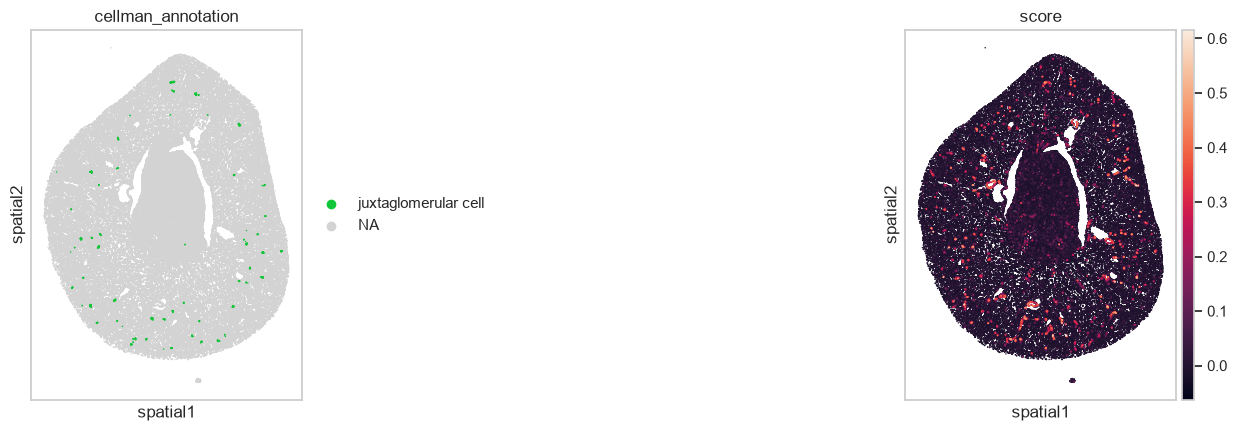

In [53]:
lst = markers[ct]
sc.tl.score_genes(anno, lst)
sc.pl.spatial(anno, color=["cellman_annotation", "score"], groups=[ct],
              spot_size=20, ncols=2, wspace=0.3)

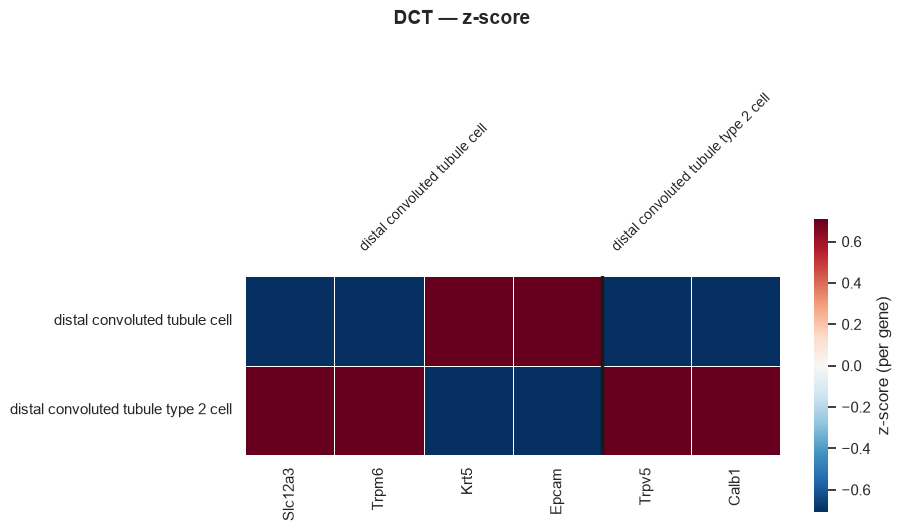

In [61]:
import numpy as np, pandas as pd, scipy.sparse as spr
import matplotlib.pyplot as plt, seaborn as sns

def plot_marker_zheatmap(celltypes, adata, col="cellman_annotation", name="",
                         max_cells_per_type=3000,
                         cell_w=0.7, cell_h=1.1, figsize=None,
                         label_fs=11, tick_fs=11):
    """y = celltypes, x = 각 celltype 마커(get_markers; 조상 포함), 값 = 유전자별 z-score.
    cell_w/cell_h = 유전자열/행 하나의 크기(inch). figsize를 직접 주면 그걸 우선."""
    mk = get_markers(celltypes, adata=adata)
    used, blocks, kept = set(), {}, []
    for ct in celltypes:
        gs = [g for g in mk.get(ct, []) if not (g in used or used.add(g))]
        if gs:
            blocks[ct] = gs; kept.append(ct)
        else:
            print(f"[warn] {ct!r}: 데이터에 마커 없음 — skip")
    if not kept:
        print("plot 없음"); return
    genes = [g for v in blocks.values() for g in v]

    lab = adata.obs[col].astype(str)
    sub = adata[lab.isin(kept)].copy()
    lv, rng, keep = sub.obs[col].astype(str).values, np.random.default_rng(0), []
    for ct in kept:
        ci = np.flatnonzero(lv == ct)
        keep.append(rng.choice(ci, max_cells_per_type, replace=False) if len(ci) > max_cells_per_type else ci)
    sub = sub[np.sort(np.concatenate(keep))].copy()

    X = sub[:, genes].X
    X = X.toarray() if spr.issparse(X) else np.asarray(X)
    M  = (pd.DataFrame(X, columns=genes, index=sub.obs[col].astype(str).values)
            .groupby(level=0).mean().loc[kept, genes])
    Mz = (M - M.mean(0)) / M.std(0).replace(0, 1)
    vmax = float(np.nanmax(np.abs(Mz.values))) or 1.0

    if figsize is None:
        figsize = (max(8, cell_w * len(genes) + 4), max(5, cell_h * len(kept) + 4))
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(Mz, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, ax=ax, square=True,
                linewidths=0.6, linecolor="white", cbar_kws=dict(label="z-score (per gene)", shrink=0.5))
    bounds = np.cumsum([len(v) for v in blocks.values()]); starts = np.concatenate([[0], bounds[:-1]])
    for x in bounds[:-1]:
        ax.axvline(x, color="k", lw=2.5)
    for ct, s0, e0 in zip(kept, starts, bounds):
        ax.text((s0 + e0) / 2, -0.25, ct, ha="center", va="bottom", rotation=45, fontsize=label_fs-1)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=tick_fs)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=tick_fs)
    ax.set_xlabel(""); ax.set_ylabel("")
    fig.suptitle(f"{name or 'markers'} — z-score", fontsize=label_fs+3, fontweight="bold")
    fig.tight_layout(); plt.show()

# 실행 — 크기 키움
dct = ['distal convoluted tubule cell', 'distal convoluted tubule type 2 cell']
plot_marker_zheatmap(dct, anno, name="DCT", cell_w=0.9, cell_h=1.4)   # 더 키우려면 값 ↑
# 또는 완전 수동: plot_marker_zheatmap(dct, anno, name="DCT", figsize=(12, 6))


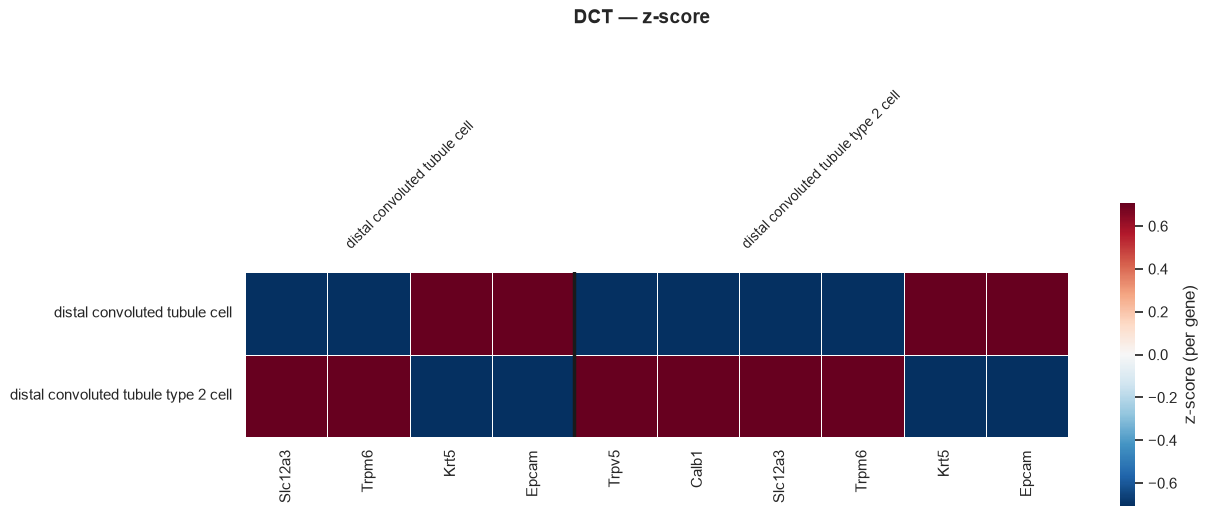

In [62]:
import numpy as np, pandas as pd, scipy.sparse as spr
import matplotlib.pyplot as plt, seaborn as sns

def plot_marker_zheatmap(celltypes, adata, col="cellman_annotation", name="",
                         max_cells_per_type=3000,
                         cell_w=0.9, cell_h=1.4, figsize=None,
                         label_fs=11, tick_fs=11):
    """y = celltypes, x = 각 celltype의 마커(get_markers; 조상 포함, 블록 간 중복 제거 안 함),
    값 = 유전자별 z-score. 공유 마커는 각 celltype 블록에 모두 나타남."""
    mk = get_markers(celltypes, adata=adata)
    blocks, kept = {}, []
    for ct in celltypes:
        gs = mk.get(ct, [])                       # ← cross-block dedup 없음 (celltype 내부 dedup은 get_markers가 함)
        if gs:
            blocks[ct] = gs; kept.append(ct)
        else:
            print(f"[warn] {ct!r}: 데이터에 마커 없음 — skip")
    if not kept:
        print("plot 없음"); return

    genes_full   = [g for v in blocks.values() for g in v]        # 중복 포함 (그림용)
    genes_unique = list(dict.fromkeys(genes_full))               # 발현 추출용

    lab = adata.obs[col].astype(str)
    sub = adata[lab.isin(kept)].copy()
    lv, rng, keep = sub.obs[col].astype(str).values, np.random.default_rng(0), []
    for ct in kept:
        ci = np.flatnonzero(lv == ct)
        keep.append(rng.choice(ci, max_cells_per_type, replace=False) if len(ci) > max_cells_per_type else ci)
    sub = sub[np.sort(np.concatenate(keep))].copy()

    X = sub[:, genes_unique].X
    X = X.toarray() if spr.issparse(X) else np.asarray(X)
    M  = (pd.DataFrame(X, columns=genes_unique, index=sub.obs[col].astype(str).values)
            .groupby(level=0).mean().loc[kept, genes_unique])
    Mz = (M - M.mean(0)) / M.std(0).replace(0, 1)
    Mz = Mz[genes_full]                                          # ← 중복 컬럼으로 펼침
    vmax = float(np.nanmax(np.abs(Mz.values))) or 1.0

    if figsize is None:
        figsize = (max(8, cell_w * len(genes_full) + 4), max(5, cell_h * len(kept) + 4))
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(Mz, cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax, ax=ax, square=True,
                linewidths=0.6, linecolor="white", cbar_kws=dict(label="z-score (per gene)", shrink=0.5))
    bounds = np.cumsum([len(v) for v in blocks.values()]); starts = np.concatenate([[0], bounds[:-1]])
    for x in bounds[:-1]:
        ax.axvline(x, color="k", lw=2.5)
    for ct, s0, e0 in zip(kept, starts, bounds):
        ax.text((s0 + e0) / 2, -0.25, ct, ha="center", va="bottom", rotation=45, fontsize=label_fs-1)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=tick_fs)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=tick_fs)
    ax.set_xlabel(""); ax.set_ylabel("")
    fig.suptitle(f"{name or 'markers'} — z-score", fontsize=label_fs+3, fontweight="bold")
    fig.tight_layout(); plt.show()

# 실행
dct = ['distal convoluted tubule cell', 'distal convoluted tubule type 2 cell']
plot_marker_zheatmap(dct, anno, name="DCT")


In [5]:
ref = sc.read_h5ad('/bce/groups/pnucolab/analysis/l202255179/UNNAMED/cellman_paper/data/xenium/ref_shamR.h5ad')
ref

AnnData object with n_obs × n_vars = 85880 × 299
    obs: 'x_centroid', 'y_centroid', 'n_genes', 'n_counts', 'ident', 'region', 'celltype_plot', 'time', 'CN'
    uns: 'CN_colors', 'celltype_plot_colors', 'ident_colors', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

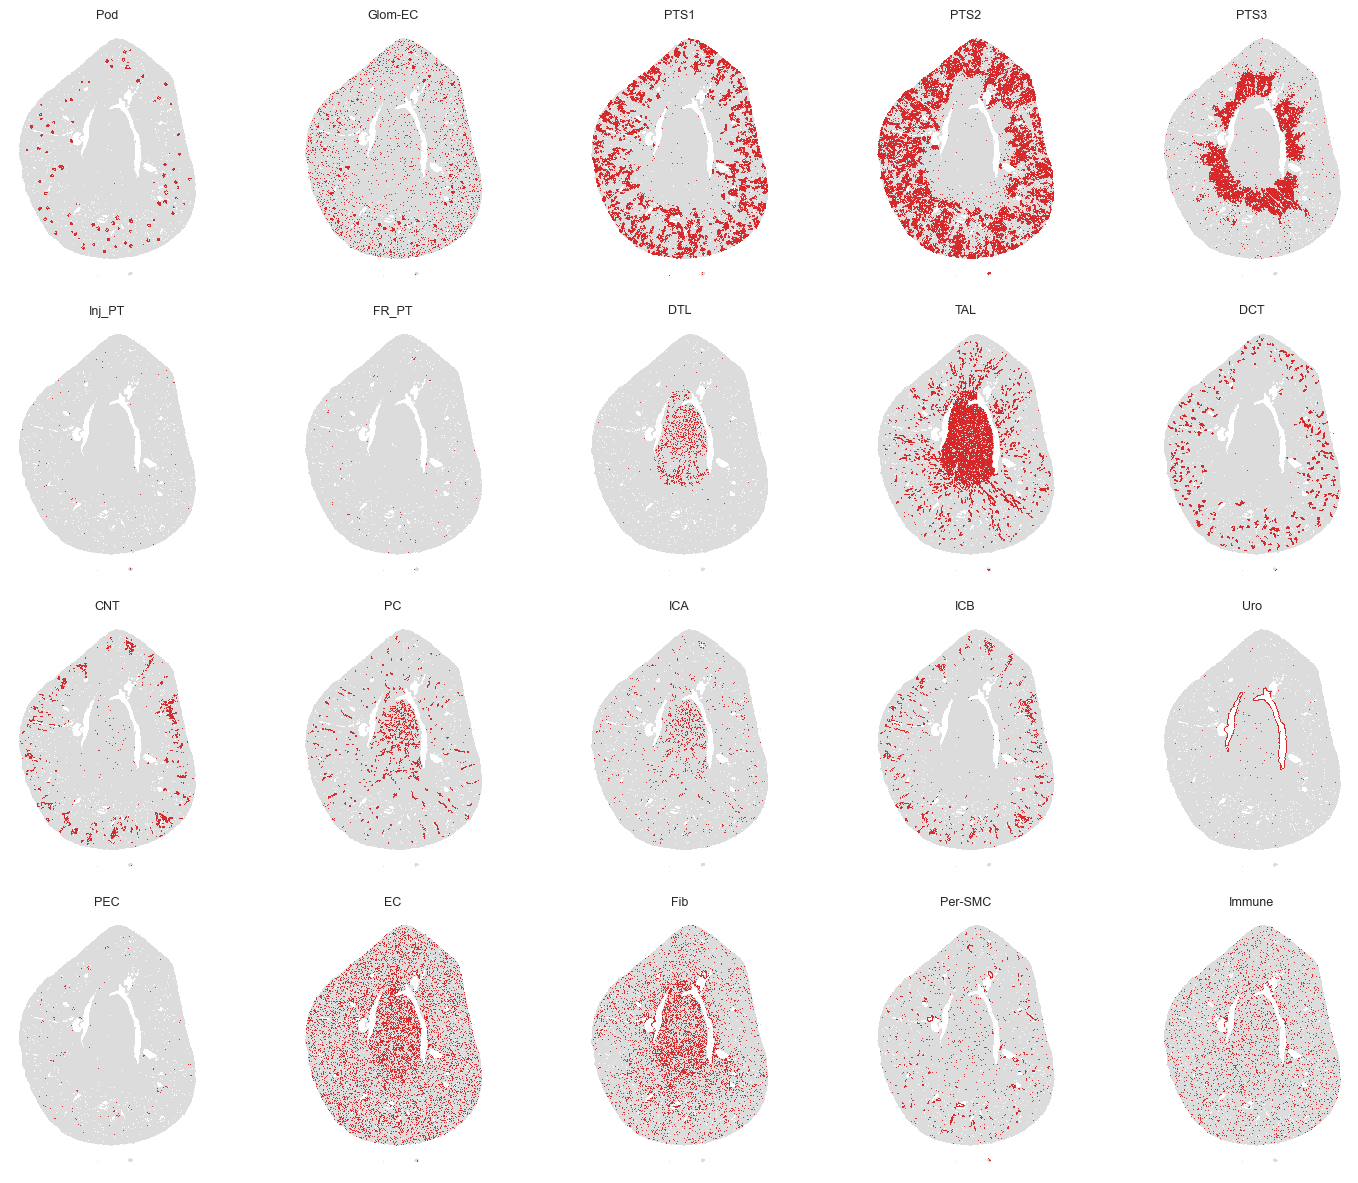

In [9]:
import math, matplotlib.pyplot as plt
COL='celltype_plot'; PS=0.5; N_COLS=5; BG='#dcdcdc'; FG='#d62728'
xy = ref.obsm['spatial']; labels = ref.obs[COL].astype(str).to_numpy()
cats = list(ref.obs[COL].cat.categories); n=len(cats)
n_cols=min(N_COLS,n); n_rows=math.ceil(n/n_cols)
fig,axes=plt.subplots(n_rows,n_cols,figsize=(3*n_cols,3*n_rows),squeeze=False)
for a_ in axes.flat: a_.set_axis_off()
for i,ct in enumerate(cats):
    a_=axes[i//n_cols,i%n_cols]; m=labels==ct
    a_.scatter(xy[~m,0],xy[~m,1],s=PS,c=BG,linewidths=0,rasterized=True)
    a_.scatter(xy[m,0], xy[m,1], s=PS,c=FG,linewidths=0,rasterized=True)
    a_.set_title(ct,fontsize=9); a_.set_aspect('equal'); a_.invert_yaxis()
fig.tight_layout(); plt.show()

## Step 6 — `map_celltypes`

`map_celltypes` picks the **GPU** implementation automatically when a CUDA device is available (`force_cpu=True` forces CPU). `method='corr'` is the default for transcript data.

In [3]:
ANNO = f"{STORE}/annotation_out/mouse_kidney_cls_annotated.h5ad" 

In [2]:
import spatialdata as sd
sdata = sd.read_zarr(ZARR)
sdata

SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (84419, 300)
with coordinate systems:
    ▸ 'global'

In [5]:
ds = cms.Dataset(STORE)
analysis = cms.Analysis(ds, ncores=NCORES, verbose=True)

zarr keys: ['centroids', 'cluster_labels', 'coordinate_bounds', 'coordinate_offset', 'downsampled_vectors', 'downsampled_vf_norm', 'genes', 'normalized_vectors', 'original_coordinate_bounds']
Loaded existing local maxima.
Loaded a precomputed normalized vector.


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at mouse_kidney_cls.h5ad is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at celltype_index.csv is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/group.py:3559: ZarrUserWarning: Object at annotation_out is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


Loaded existing gene list.
Loaded existing cluster labels.


In [6]:
sdata = analysis.map_celltypes(sdata, method="corr", gpu_device=DEVICE, h5ad=ANNO)
sdata

[map_celltypes] building centroids from mouse_kidney_cls_annotated.h5ad: 28 celltypes, 258583 vectors
    id=  0  juxtaglomerular cell              [celltype]  (1025 vectors)
    id=  1  mural cell                        [celltype]  (6375 vectors)
    id=  2  fibroblast                        [celltype]  (9711 vectors)
    id=  3  arterial endothelial cell         [celltype]  (6624 vectors)
    id=  4  endothelial cell                  [celltype]  (13011 vectors)
    id=  5  glomerular endothelial cell       [celltype]  (8074 vectors)
    id=  6  lymphatic endothelial cell        [celltype]  (1519 vectors)
    id=  7  leukocyte                         [celltype]  (3524 vectors)
    id=  8  macrophage                        [celltype]  (5410 vectors)
    id=  9  cortical thick ascending limb cell  [celltype]  (15928 vectors)
    id= 10  collecting duct epithelial cell   [celltype]  (826 vectors)
    id= 11  collecting duct principal cell    [celltype]  (9349 vectors)
    id= 12  type A 

/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=41, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)


[map_celltypes] wrote cluster_labels (258583,) + centroids (28, 541) + celltype_names (28) + colors (normalized_vectors untouched)
[map_celltypes] wrote /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/cellman_spatial/celltype_index.csv
map_celltypes: GPU path (cuda:1)


/bce/groups/pnucolab/analysis/l202255179/UNNAMED/.venv/lib/python3.11/site-packages/zarr/core/dtype/npy/string.py:249: UnstableSpecificationWarning: The data type (FixedLengthUTF32(length=23, endianness='little')) does not have a Zarr V3 specification. That means that the representation of arrays saved with this data type may change without warning in a future version of Zarr Python. Arrays stored with this data type may be unreadable by other Zarr libraries. Use this data type at your own risk! Check https://github.com/zarr-developers/zarr-extensions/tree/main/data-types for the status of data type specifications for Zarr V3.
  v3_unstable_dtype_warning(self)
KDE chunk 122/122: 100%|██████████| 3/3 [00:00<00:00,  5.40it/s]


[map_celltypes] tables['cellman_downsampled'] (258583, 541) 28 celltypes


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
└── Tables
      ├── 'cellman_downsampled': AnnData (258583, 541)
      └── 'table': AnnDa

In [7]:
sdata = analysis.filter_celltypemaps(sdata, min_r=0.6)
sdata

[write_celltype_map] labels['cellman_celltype_map'] (5075, 4242) + images['cellman_celltype_map_rgb'] (28 celltypes) @ 1.0µm/px, origin=(0.7,1.2)


SpatialData object, with associated Zarr store: /bce/groups/pnucolab/analysis/l202255179/UNNAMED/CeLLMan_notebooks/ST_bench/xenium_kidney/ShamR/spatialdata.zarr
├── Images
│     ├── 'cellman_celltype_map_rgb': DataArray[cyx] (3, 5075, 4242)
│     ├── 'morphology_focus': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
│     └── 'morphology_mip': DataTree[cyx] (1, 23888, 19971), (1, 11944, 9985), (1, 5972, 4992), (1, 2986, 2496), (1, 1493, 1248)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
│     ├── 'cellman_celltype_map': DataArray[yx] (5075, 4242)
│     └── 'nucleus_labels': DataTree[yx] (23888, 19971), (11944, 9985), (5972, 4992), (2986, 2496), (1493, 1248)
├── Points
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 10) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (84419, 1) (2D shapes)
│     └── 'nucleus_boundaries': Geo

In [9]:
ds.extract_spatialdata_scale(sdata)

(np.float64(4.705882352941177), np.float64(4.705882352941177))

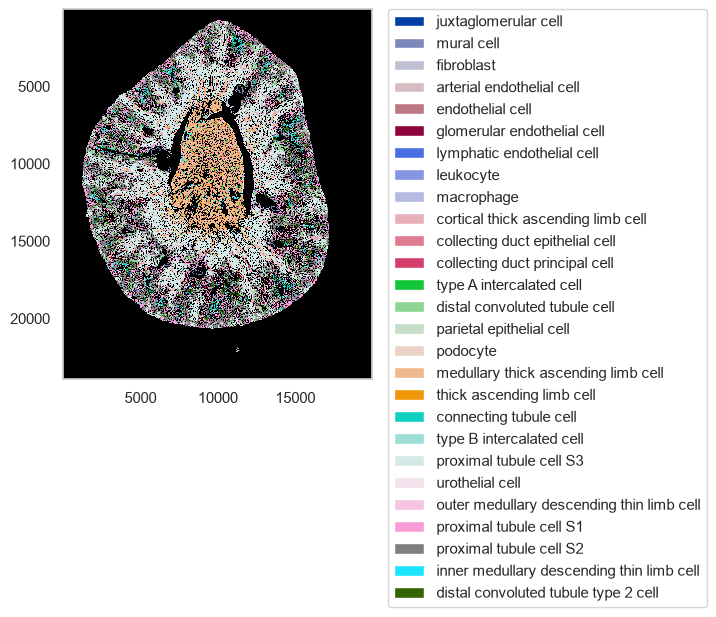

In [10]:
ds.plot_celltypes_map(show_annotation=True)

In [11]:
sdata.labels['cellman_celltype_map']

<xarray.DataArray 'image' (y: 5075, x: 4242)> Size: 86MB
dask.array<array, shape=(5075, 4242), dtype=int32, chunksize=(5075, 4242), chunktype=numpy.ndarray>
Coordinates:
  * y        (y) float64 41kB 0.5 1.5 2.5 3.5 ... 5.072e+03 5.074e+03 5.074e+03
  * x        (x) float64 34kB 0.5 1.5 2.5 3.5 ... 4.24e+03 4.24e+03 4.242e+03
Attributes:
    transform:  {'global': Affine (x, y -> x, y)\n    [1.         0.         ...

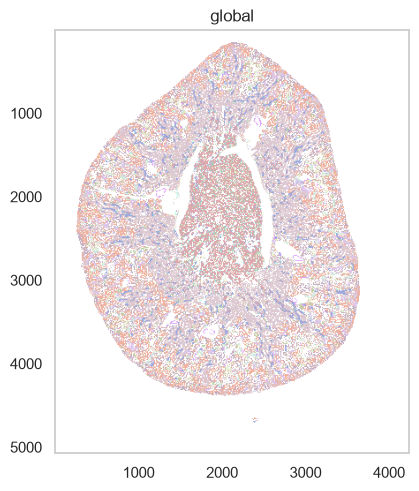

In [13]:
import spatialdata_plot
sdata.pl.render_labels("cellman_celltype_map").pl.show()


In [16]:
import numpy as np
arr = np.asarray(sdata.labels["cellman_celltype_map"].data)   # (y, x) int32
names, colors = analysis._celltype_names_colors()
{names[i-1]: int((arr == i).sum()) for i in np.unique(arr) if i > 0}
# → {'Paneth cell': 23, 'goblet cell': 28, 'T cell': 29}   ← 실측 동작


{'juxtaglomerular cell': 11458,
 'mural cell': 59780,
 'fibroblast': 87706,
 'arterial endothelial cell': 41325,
 'endothelial cell': 54637,
 'glomerular endothelial cell': 52764,
 'lymphatic endothelial cell': 30766,
 'leukocyte': 40924,
 'macrophage': 44293,
 'cortical thick ascending limb cell': 439266,
 'collecting duct epithelial cell': 25488,
 'collecting duct principal cell': 79925,
 'type A intercalated cell': 57874,
 'distal convoluted tubule cell': 241050,
 'parietal epithelial cell': 6280,
 'podocyte': 68622,
 'medullary thick ascending limb cell': 752121,
 'thick ascending limb cell': 119518,
 'connecting tubule cell': 157064,
 'type B intercalated cell': 106069,
 'proximal tubule cell S3': 2412627,
 'urothelial cell': 35404,
 'outer medullary descending thin limb cell': 63327,
 'proximal tubule cell S1': 669960,
 'proximal tubule cell S2': 1262731,
 'inner medullary descending thin limb cell': 28806,
 'distal convoluted tubule type 2 cell': 158878}

/home/l202255179/.local/share/uv/python/cpython-3.11.13-linux-x86_64-gnu/lib/python3.11/functools.py:909: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


IndexError: Boolean index has wrong length: 28 instead of 27

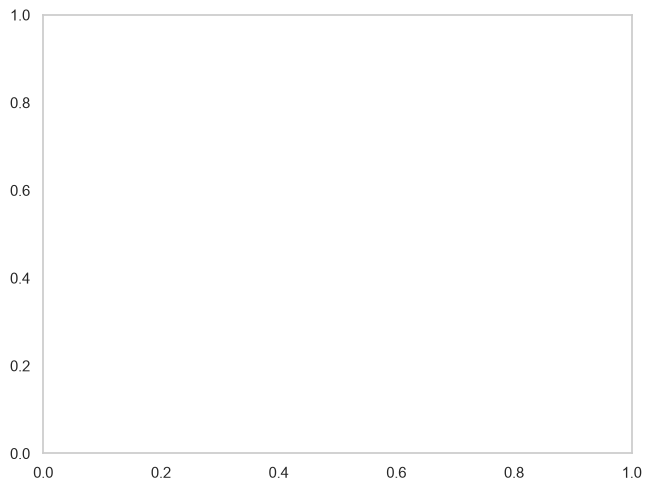

In [19]:
from spatialdata.models import TableModel
import anndata as ad
import pandas as pd

K = len(names)
t = ad.AnnData(obs=pd.DataFrame({
    "instance_id": np.arange(1, K + 1, dtype=np.int64),
    "region": pd.Categorical(["cellman_celltype_map"] * K),
    "celltype": pd.Categorical(names, categories=names)}))
t.uns["celltype_colors"] = colors
sdata.tables["_legend"] = TableModel.parse(
    t, region="cellman_celltype_map", region_key="region", instance_key="instance_id")

sdata.pl.render_labels("cellman_celltype_map", color="celltype",
                       table_name="_legend", fill_alpha=1.0).pl.show()
